### Let's answer questions like:
- How many unique players are there?
- What years are covered?
- What is the average number of runs a player scores in a single year?

In [6]:
import pandas as pd

# Load batting data
batting = pd.read_csv('Batting.csv')

In [10]:
batting.head()
# use .head() to make sure the import worked as what expect

,playerID,yearID,stint,teamID,lgID,G,AB,R,H,2B,...,RBI,SB,CS,BB,SO,IBB,HBP,SH,SF,GIDP
0,aardsda01,2004,1,SFN,NL,11,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,aardsda01,2006,1,CHN,NL,45,2,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,1.0,0.0,0.0
2,aardsda01,2007,1,CHA,AL,25,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,aardsda01,2008,1,BOS,AL,47,1,0,0,0,...,0.0,0.0,0.0,0,1.0,0.0,0.0,0.0,0.0,0.0
4,aardsda01,2009,1,SEA,AL,73,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
batting.describe()
# use .describe() to see some initial information

,yearID,stint,G,AB,R,H,2B,3B,HR,RBI,SB,CS,BB,SO,IBB,HBP,SH,SF,GIDP
count,128598.000000,128598.000000,128598.000000,128598.000000,128598.000000,128598.000000,128598.000000,128598.000000,128598.000000,127842.000000,126052.000000,96103.000000,128598.000000,119739.000000,82071.000000,125782.000000,122530.000000,81934.000000,93166.000000
mean,1967.529091,1.090515,47.295798,129.389376,17.290953,33.766272,5.768674,1.154497,2.688300,15.708726,2.721052,1.108394,11.926523,20.160190,0.962411,1.014120,2.032196,0.983792,2.767780
std,40.919857,0.314065,45.837715,177.034184,26.956123,50.054548,9.272108,2.461973,6.197295,25.249239,7.197206,2.608783,19.727894,29.328141,2.590036,2.250185,3.942554,1.893025,4.589461
min,1871.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1933.000000,1.000000,11.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1975.000000,1.000000,31.000000,40.000000,3.000000,7.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000,2.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2004.000000,1.000000,71.000000,195.000000,24.000000,48.000000,8.000000,1.000000,2.000000,21.000000,2.000000,1.000000,16.000000,28.000000,1.000000,1.000000,2.000000,1.000000,4.000000
max,2025.000000,6.000000,165.000000,716.000000,198.000000,262.000000,67.000000,36.000000,73.000000,191.000000,138.000000,42.000000,232.000000,223.000000,120.000000,51.000000,67.000000,19.000000,36.000000


batting.describe() give use the answer to question one! the dataset begins in the year 1871 and goes all the way to 2025.
- and also found values by useing batting['yearID'].min() & batting['yearID'].max()

In [15]:
batting['yearID'].min()

np.int64(1871)

In [17]:
batting['yearID'].max()

np.int64(2025)

In [20]:
# to find the number of unique players in the dataset, we can use:
batting['playerID'].unique()
# to get the number immediately without having to use .size

<StringArray>
['aardsda01', 'aaronha01', 'aaronto01',  'aasedo01',  'abadan01',  'abadfe01',
 'abadijo01', 'abbated01', 'abbeybe01', 'abbeych01',
 ...
 'zulueyo01', 'zumayjo01', 'zuniggu01', 'zuninmi01', 'zupcibo01',  'zupofr01',
 'zuvelpa01', 'zuverge01', 'zwilldu01',  'zychto01']
Length: 24011, dtype: str

### Filtering out inactive player
- helpful to look through the data before jumping into any heavy analysis
- because there are often quirks to the data that can be hard to spot without subject matter expertise

In [22]:
# make a new DataFrame containing only the players that had at least one "at bat" in a given year:
active_players = batting[batting['AB'] > 0]
active_players.describe()

,yearID,stint,G,AB,R,H,2B,3B,HR,RBI,SB,CS,BB,SO,IBB,HBP,SH,SF,GIDP
count,106470.000000,106470.000000,106470.000000,106470.000000,106470.000000,106470.000000,106470.000000,106470.000000,106470.000000,105715.000000,103927.000000,74495.000000,106470.000000,97871.000000,60574.000000,103657.000000,100421.000000,60441.000000,71564.000000
mean,1961.015610,1.087217,52.752775,156.280783,20.881253,40.784024,6.967597,1.394440,3.247018,18.996500,3.299662,1.429358,14.402808,24.664722,1.303942,1.230385,2.477330,1.333532,3.603250
std,40.618563,0.309582,47.736202,183.445456,28.332393,52.344675,9.771709,2.643194,6.676413,26.617856,7.804549,2.884041,20.843173,30.679386,2.940012,2.424457,4.226708,2.095587,4.940732
min,1871.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1928.000000,1.000000,13.000000,14.000000,1.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1964.000000,1.000000,35.000000,68.000000,7.000000,14.000000,2.000000,0.000000,0.000000,6.000000,0.000000,0.000000,4.000000,13.000000,0.000000,0.000000,1.000000,0.000000,1.000000
75%,1998.000000,1.000000,85.000000,255.000000,32.000000,65.000000,11.000000,2.000000,3.000000,28.000000,3.000000,2.000000,21.000000,34.000000,1.000000,1.000000,3.000000,2.000000,6.000000
max,2025.000000,6.000000,165.000000,716.000000,198.000000,262.000000,67.000000,36.000000,73.000000,191.000000,138.000000,42.000000,232.000000,223.000000,120.000000,51.000000,67.000000,19.000000,36.000000


as expected, the average number of runs scored by a player shot up to 20.88 `R` after filtering out all of the players who were always on the bench.

### Finding top performers using Group By
- if we use .groupby() we can find statistics for a particular player, year, or even team.

In [24]:
# find the total number of career home runs for each player with this:
batting.groupby('playerID')['HR'].sum().sort_values(ascending=False)

playerID
bondsba01    762
aaronha01    755
ruthba01     714
pujolal01    703
rodrial01    696
            ... 
abadijo01      0
abadfe01       0
zmiched01      0
abbotky01      0
zettlge01      0
Name: HR, Length: 24011, dtype: int64

- `.groupby('playerID')` groups all rows that belong to the same player
- `['HR']` selects only the home runs column from each group
- `.sum()` is an aggregate function. it adds up the home runs within each player's group, giving us each player's career total.
- if wated the average number of home runs per year, use: `.mean()`
- `.sort_values(ascending=False)` sorts the results so the players with the most home runs appear first

In [27]:
# filtering for only Babe Ruth's rows
babe_ruth = batting[batting['playerID'] == 'ruthba01']

# finding the starting and ending years
start_year = babe_ruth['yearID'].min()
end_year = babe_ruth['yearID'].max()

In [29]:
# filtering for players that played the same years as Babe
ruth_years = batting[(batting['yearID'] >= start_year) & (batting['yearID'] <= end_year)]

# finding the home run leaders during that time
ruth_years.groupby('playerID')['HR'].sum().sort_values(ascending=False)

playerID
ruthba01     714
gehrilo01    378
foxxji01     302
hornsro01    300
simmoal01    256
            ... 
zapusjo01      0
zahnipa01      0
zabelzi01      0
youngch02      0
youngch01      0
Name: HR, Length: 4689, dtype: int64

### Graphing Data by Year

In [31]:
# let fidn the total numberr of home runs per year
total_hr_by_year = batting.groupby('yearID')['HR'].sum()

#### we can now plot this using Matplotlib's.
- .plot() function.
- this function need a list of X ana Y values.
- we want the year to be on the X axis and the total nubmer of home runs to be on the Y axis:

In [40]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 1.4 MB/s eta 0:00:000:00:010:00:0102
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 915.2 kB/s eta 0:00:00 kB/s eta 0:00:01:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.8 MB/s eta 0:00:001.8 MB/s eta 0:00:01
Using cached pillow-12.3.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


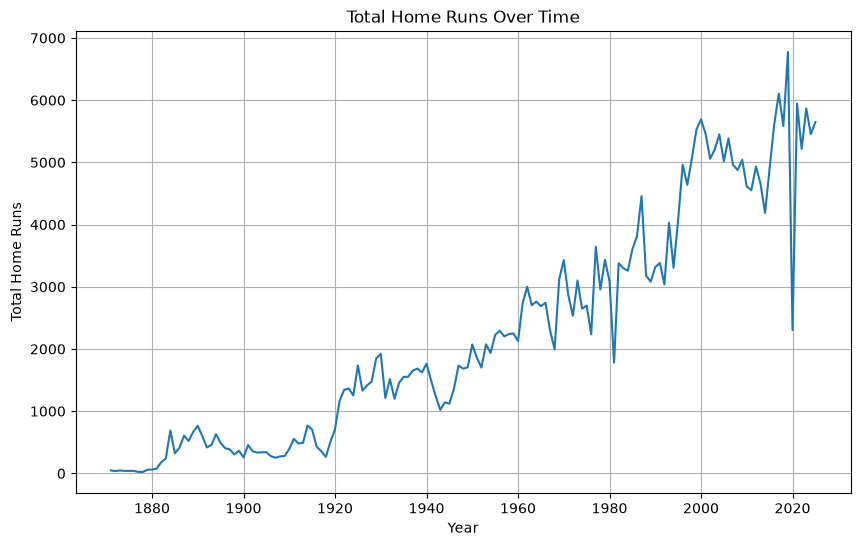

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(total_hr_by_year.index, total_hr_by_year.values)

# adding labels
plt.title('Total Home Runs Over Time')
plt.xlabel('Year')
plt.ylabel('Total Home Runs')

plt.grid(True)
plt.show()

### Your favorite team vs The league
I grew up in Denver, so my team is the Colorado Rockies, who have been laughably bad for the majority of my life.
Let's graph the Rockies'home runs every year against the league average

In [45]:
# first, we can group the data by year and team to find each team's home runs for a given year:
team_hr_per_year = (
    batting
    .groupby(['yearID', 'teamID'])['HR']
    .sum()
    .reset_index()
)

In [47]:
# then, to find the Rockies specifically, we can filter by `teamID`:
rockies_hr = (
    team_hr_per_year
    [team_hr_per_year['teamID'] == 'COL']
    .set_index('yearID')['HR']
)

In [49]:
# we can also find the eague average for each year. we'll also filter out anything before 1993, since that is the year the Rockies were crated:
league_avg_hr = (
    team_hr_per_year
    .groupby('yearID')['HR']
    .mean()
)

league_avg_hr = league_avg_hr[league_avg_hr.index >= 1993]

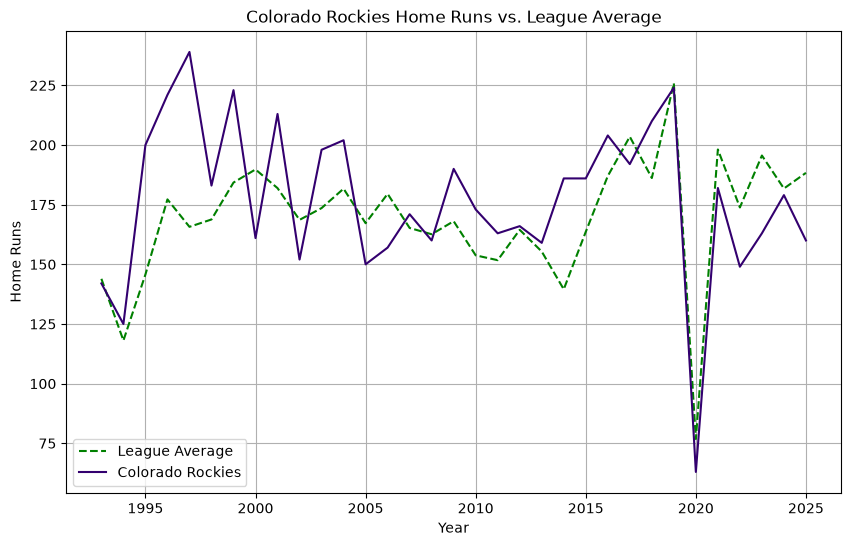

In [52]:
# we can put this all together by graphing these two lines:
plt.figure(figsize=(10, 6))

plt.plot(league_avg_hr.index,
         league_avg_hr.values,
         label='League Average',
         color='green',
         linestyle='--'
)

plt.plot(
    rockies_hr.index,
    rockies_hr.values,
    label='Colorado Rockies',
    color='#33006f'
)

plt.title('Colorado Rockies Home Runs vs. League Average')
plt.xlabel('Year')
plt.ylabel('Home Runs')
plt.legend()

plt.grid(True)
plt.show()